# Proyek Klasifikasi Gambar: Animals-10

- **Dataset**: Animals-10 (Kaggle, ~26 ribu gambar, 10 kelas, resolusi tidak seragam)
- **Model**: Sequential + Conv2D + Pooling (TensorFlow/Keras)
- **Output**: SavedModel, TF-Lite, TFJS

> Jalankan di Google Colab (Runtime > Change runtime type > T4 GPU), lalu **Run all** sampai selesai sebelum didownload.

## 1. Instalasi & Import

In [1]:
!pip install -q split-folders tensorflowjs kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pysal 25.7 requires packaging>=22, but you have packaging 20.9 which is incompatible.
google-adk 2.7.1 requires packaging>=21, but you have packaging 20.9 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
libpysal 4.14.1 requires packaging>=23.2, but you have packaging 20.9 which is incompatible.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
db-dtypes 1.9.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
shap 0.54.1 requires packaging>20.9, but you have packaging 20.9 which is incompatible.
scikit-image 0.25.2 requires packagin

In [2]:
import os, shutil, random, pathlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import splitfolders

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download Dataset

In [3]:
import kagglehub
path = kagglehub.dataset_download("alessiocorrado99/animals10")
RAW_DIR = os.path.join(path, "raw-img")
print(RAW_DIR, os.listdir(RAW_DIR))

Using Colab cache for faster access to the 'animals10' dataset.
/kaggle/input/animals10/raw-img ['cavallo', 'pecora', 'elefante', 'gatto', 'scoiattolo', 'gallina', 'ragno', 'mucca', 'cane', 'farfalla']


## 3. Eksplorasi Data (jumlah gambar & resolusi)

In [4]:
def print_images_resolution(directory):
    unique_sizes = set()
    total_images = 0
    for subdir in sorted(os.listdir(directory)):
        subdir_path = os.path.join(directory, subdir)
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        print(f"{subdir}: {num_images}")
        total_images += num_images
        for img_file in image_files[:300]:  # sampel agar cepat
            with Image.open(os.path.join(subdir_path, img_file)) as img:
                unique_sizes.add(img.size)
    print(f"\nTotal gambar: {total_images}")
    print(f"Jumlah variasi resolusi (dari sampel): {len(unique_sizes)}")
    print("Contoh resolusi:", list(unique_sizes)[:8])

print_images_resolution(RAW_DIR)

cane: 4863
cavallo: 2623
elefante: 1446
farfalla: 2112
gallina: 3098
gatto: 1668
mucca: 1866
pecora: 1820
ragno: 4821
scoiattolo: 1862

Total gambar: 26179
Jumlah variasi resolusi (dari sampel): 430
Contoh resolusi: [(640, 320), (300, 270), (300, 279), (640, 576), (282, 221), (300, 126), (300, 135), (238, 300)]


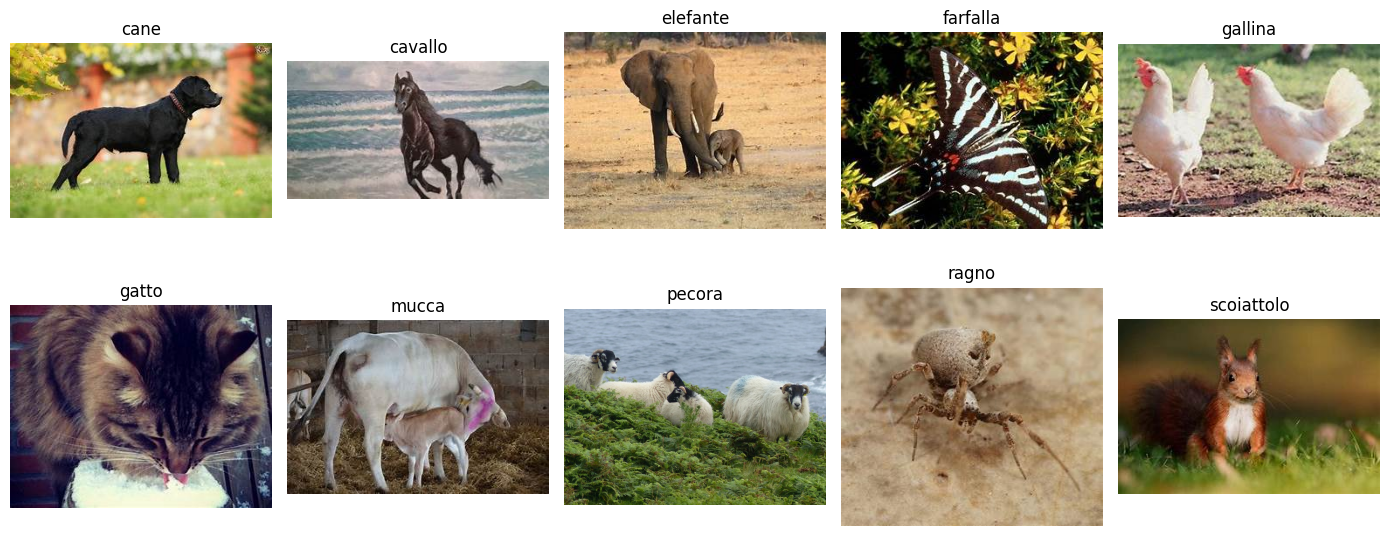

In [5]:
classes = sorted(os.listdir(RAW_DIR))
plt.figure(figsize=(14, 6))
for i, c in enumerate(classes):
    f = random.choice(os.listdir(os.path.join(RAW_DIR, c)))
    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(os.path.join(RAW_DIR, c, f)))
    plt.title(c); plt.axis("off")
plt.tight_layout(); plt.show()

## 4. Split Dataset: Train 80% / Validation 10% / Test 10%

In [6]:
DATA_DIR = "dataset"
if os.path.exists(DATA_DIR):
    shutil.rmtree(DATA_DIR)
splitfolders.ratio(RAW_DIR, output=DATA_DIR, seed=SEED, ratio=(0.8, 0.1, 0.1))

# Nama folder di dataset ini berbahasa Italia, kita terjemahkan ke Inggris
translate = {"cane":"dog","cavallo":"horse","elefante":"elephant","farfalla":"butterfly",
             "gallina":"chicken","gatto":"cat","mucca":"cow","pecora":"sheep",
             "ragno":"spider","scoiattolo":"squirrel"}
for split in ["train", "val", "test"]:
    for it, en in translate.items():
        src = os.path.join(DATA_DIR, split, it)
        if os.path.exists(src):
            os.rename(src, os.path.join(DATA_DIR, split, en))

for split in ["train", "val", "test"]:
    n = sum(len(files) for _, _, files in os.walk(os.path.join(DATA_DIR, split)))
    print(split, ":", n, "gambar")

Copying files: 26179 files [03:36, 120.69 files/s]

train : 20938 gambar
val : 2614 gambar
test : 2627 gambar


## 5. Load Data

In [7]:
IMG_SIZE = (150, 150)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train", image_size=IMG_SIZE, batch_size=BATCH, seed=SEED, shuffle=True)
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/val", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(class_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 20938 files belonging to 10 classes.
Found 2614 files belonging to 10 classes.
Found 2627 files belonging to 10 classes.
['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


## 6. Membangun Model

Augmentasi dipasang sebagai layer di awal model, sehingga **hanya aktif saat training** (data validasi/test tidak diaugmentasi).

Ada dua pilihan:
- `USE_TRANSFER_LEARNING = False` : CNN dari nol (biasanya ~80-90%).
- `USE_TRANSFER_LEARNING = True` : MobileNetV2 + Conv2D & Pooling (biasanya >95%).

In [8]:
USE_TRANSFER_LEARNING = True

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="augmentation")

def build_scratch():
    model = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        augmentation,
        layers.Rescaling(1./255),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    return model

def build_transfer():
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    model = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        augmentation,
        layers.Rescaling(1./127.5, offset=-1),
        base,
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    return model

model = build_transfer() if USE_TRANSFER_LEARNING else build_scratch()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

/tmp/ipykernel_1044/3518119256.py:36: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 5, 5, 128)      │     1,474,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,733,962 (14.24 MB)

 Trainable params: 1,475,978 (5.63 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Training dengan Callback

In [9]:
class StopAt95(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get("accuracy", 0) >= 0.95 and logs.get("val_accuracy", 0) >= 0.95:
            print("\nAkurasi training & validasi sudah >= 95%, training dihentikan.")
            self.model.stop_training = True

cbs = [
    StopAt95(),
    callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

EPOCHS = 20 if USE_TRANSFER_LEARNING else 50
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cbs)

Epoch 1/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 38s 42ms/step - accuracy: 0.8109 - loss: 0.6639 - val_accuracy: 0.9109 - val_loss: 0.2971 - learning_rate: 0.0010
Epoch 2/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 26s 40ms/step - accuracy: 0.8598 - loss: 0.4364 - val_accuracy: 0.9174 - val_loss: 0.2859 - learning_rate: 0.0010
Epoch 3/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 41s 40ms/step - accuracy: 0.8711 - loss: 0.3985 - val_accuracy: 0.9231 - val_loss: 0.2529 - learning_rate: 0.0010
Epoch 4/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 29s 43ms/step - accuracy: 0.8763 - loss: 0.3836 - val_accuracy: 0.9178 - val_loss: 0.2803 - learning_rate: 0.0010
Epoch 5/20
653/655 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8848 - loss: 0.3588
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
655/655 ━━━━━━━━━━━━━━━━━━━━ 27s 40ms/step - accuracy: 0.8824 - loss: 0.3591 - val_accuracy: 0.9243 - val_loss: 0.2730 - learning_rate: 0.0010
Epoch 6/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 41s 41ms/step - accuracy: 0.8972 - los

## 8. Plot Akurasi & Loss

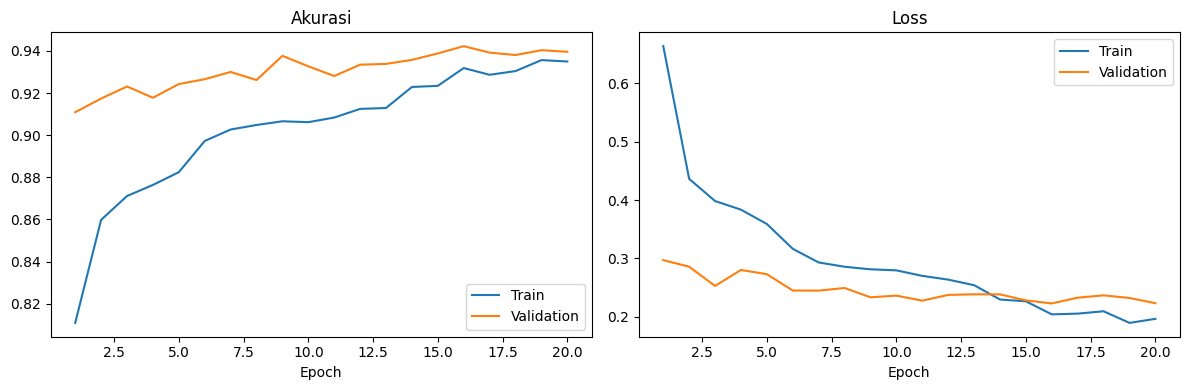

In [10]:
acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
loss, val_loss = history.history["loss"], history.history["val_loss"]
ep = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ep, acc, label="Train"); plt.plot(ep, val_acc, label="Validation")
plt.title("Akurasi"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(ep, loss, label="Train"); plt.plot(ep, val_loss, label="Validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout(); plt.show()

## 9. Evaluasi (Train, Validation, Test)

In [11]:
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss_f, val_acc_f = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Train accuracy : {train_acc*100:.2f}%")
print(f"Val accuracy   : {val_acc_f*100:.2f}%")
print(f"Test accuracy  : {test_acc*100:.2f}%")

Train accuracy : 96.57%
Val accuracy   : 94.22%
Test accuracy  : 94.21%


              precision    recall  f1-score   support

   butterfly       0.97      0.98      0.97       212
         cat       0.93      0.95      0.94       168
     chicken       0.97      0.97      0.97       311
         cow       0.85      0.90      0.88       188
         dog       0.97      0.92      0.94       487
    elephant       0.89      0.95      0.92       146
       horse       0.89      0.94      0.91       263
       sheep       0.86      0.86      0.86       182
      spider       0.99      0.98      0.99       483
    squirrel       0.96      0.94      0.95       187

    accuracy                           0.94      2627
   macro avg       0.93      0.94      0.93      2627
weighted avg       0.94      0.94      0.94      2627



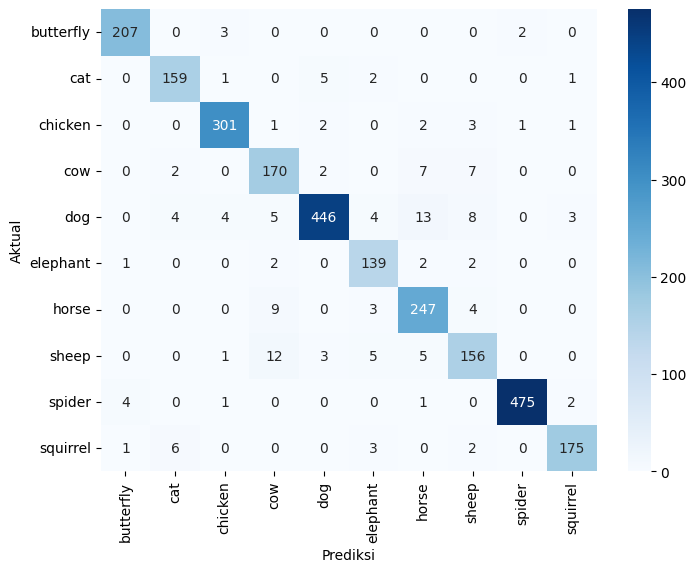

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.show()

## 10. Simpan Model: SavedModel, TF-Lite, TFJS

In [20]:
SUB = "submission"
if os.path.exists(SUB):
    shutil.rmtree(SUB)
os.makedirs(SUB)

# Model untuk deployment: tanpa layer augmentasi
infer_model = models.Sequential(
    [layers.Input(shape=IMG_SIZE + (3,))] + [l for l in model.layers if l.name != "augmentation"],
    name="inference_model")

# SavedModel
infer_model.export(f"{SUB}/saved_model")

# TF-Lite
converter = tf.lite.TFLiteConverter.from_keras_model(infer_model)
tflite_model = converter.convert()
os.makedirs(f"{SUB}/tflite", exist_ok=True)
with open(f"{SUB}/tflite/model.tflite", "wb") as f:
    f.write(tflite_model)
with open(f"{SUB}/tflite/label.txt", "w") as f:
    f.write("\n".join(class_names))

Saved artifact at 'submission/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_168')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133750720566416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720567184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720566992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720567376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720565072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720566608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720568144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720567952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720568336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133750720563536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133

In [21]:
!pip install -q uv
!uv venv --python 3.11 /content/tfjs_env
!uv pip install --python /content/tfjs_env/bin/python -q "tensorflow==2.15.1" "tensorflowjs==4.22.0" "numpy<2" "setuptools<70"
!/content/tfjs_env/bin/tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model --signature_name=serving_default --saved_model_tags=serve {SUB}/saved_model {SUB}/tfjs_model
!ls -R {SUB}/tfjs_model

Using CPython 3.11.18
Creating virtual environment at: tfjs_env
Activate with: source tfjs_env/bin/activate
2026-10-31 06:35:46.700948: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-31 06:35:46.701026: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-31 06:35:46.702779: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-31 06:35:50.233520: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-10-31 06:35:56.901013: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make su

## 11. Inference menggunakan TF-Lite

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


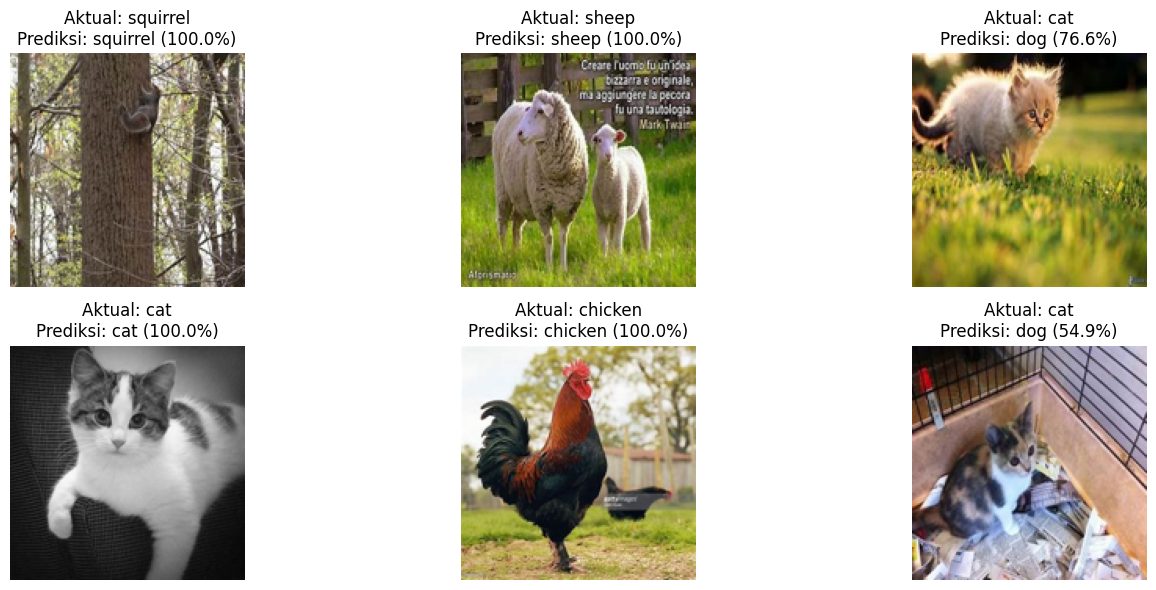

In [22]:
interpreter = tf.lite.Interpreter(model_path=f"{SUB}/tflite/model.tflite")
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

plt.figure(figsize=(15, 6))
for i in range(6):
    c = random.choice(class_names)
    fname = random.choice(os.listdir(f"{DATA_DIR}/test/{c}"))
    img = Image.open(f"{DATA_DIR}/test/{c}/{fname}").convert("RGB").resize(IMG_SIZE)
    x = np.expand_dims(np.array(img, dtype=np.float32), 0)
    interpreter.set_tensor(inp["index"], x)
    interpreter.invoke()
    pred = interpreter.get_tensor(out["index"])[0]
    plt.subplot(2, 3, i + 1)
    plt.imshow(img); plt.axis("off")
    plt.title(f"Aktual: {c}\nPrediksi: {class_names[np.argmax(pred)]} ({pred.max()*100:.1f}%)")
plt.tight_layout(); plt.show()

## 12. requirements.txt & Zip

In [23]:
!pip freeze | grep -i -E "^(tensorflow|numpy|matplotlib|pillow|scikit-learn|seaborn|split-folders|kagglehub)==" > {SUB}/requirements.txt
!echo "tensorflowjs==4.22.0" >> {SUB}/requirements.txt
!cat {SUB}/requirements.txt

kagglehub==1.0.3
matplotlib==3.10.0
numpy==2.1.3
pillow==11.3.0
scikit-learn==1.6.1
seaborn==0.13.2
split-folders==0.6.1
tensorflow==2.21.0
tensorflowjs==4.22.0


In [24]:
shutil.make_archive("submission", "zip", SUB)
print("Selesai: submission.zip")

Selesai: submission.zip
